# Tests for bilinear EDMD and Koopman-based robust control

These are the standard methods of Strässer, Schaller, Worthmann, Berberich and Allgöwer, *Koopman-based feedback design with stability guarantees*, IEEE TAC 70(1), 2025.

- **`edmd.py`:** sampled-data bilinear EDMD. From the flows of every vector field it fits

$$
\dot z = A z + B_0 u + \sum_{j=1}^m u_j B_j z, \qquad z = \hat\Phi(x),\ \hat\Phi(0) = 0,
$$

  which is equivalent to $\dot Z = A_{full} Z + \sum_j u_j B_{full,j} Z$ on $Z = [1; z]$.
  - The Koopman matrix of each flow is estimated by least squares on snapshot pairs $(x, \varphi^{\Delta t}_{f_j}(x))$, keeping Strässer's structure: a constant observable, and no constant column for the drift.
  - Generators are obtained as $\mathrm{logm}(K)/\Delta t$.
  - The flows of $f_j$ are simulated *without* drift, so each $B_j$ is estimated directly.
- **`edmd.py`, control methods:**
  - `EdmdRobustController`: Theorem 7 of the paper (LMIs (54)–(55), solved with MOSEK), giving the rational feedback $\mu(x) = (I - L_w(\Lambda^{-1}\otimes\hat\Phi(x)))^{-1} L P^{-1}\hat\Phi(x)$ with region of attraction $\{\hat\Phi(x)^\top P^{-1}\hat\Phi(x) \le 1\}$.
  - `EdmdLQR`: LQR on the linear part $(A, B_0)$ of the model.
  - `EdmdMPC`: MPC with the bilinear model as the predictor (CasADi + IPOPT, multiple shooting), tested in Part 4.

In [1]:
%load_ext autoreload
%autoreload 2
import numpy as np
import matplotlib.pyplot as plt

from dynamics import InputAffineSystem
from edmd import MonomialDictionary, CustomDictionary, bilinear_edmd
from edmd import EdmdRobustController, EdmdLQR

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
np.set_printoptions(precision=4, suppress=True)

## Part 1. Validation on Strässer et al., Example VI-A

The system is $\dot x_1 = \rho x_1$, $\dot x_2 = \lambda(x_2 - x_1^2) + u$ with $\rho = -2$ and $\lambda = 1$. The lifting $\hat\Phi = [x_1,\ x_2,\ x_2 - \tfrac{\lambda}{\lambda - 2\rho}x_1^2]$ is *exactly* invariant.

The paper reports $A = \begin{bmatrix}-2&0&0\\0&-4&5\\0&0&1\end{bmatrix}$, $B_0 = [0, 1, 1]^\top$ and $B_1 = 0$. With $c_r = 0.1$, $Q_z = -I$, $S_z = 0$ and $R_z = 500$, it obtains $\mu = [0.00,\ -3.77,\ -3.46]\,\hat\Phi(x)$, whose region of attraction is shown in its Fig. 2 (roughly $|x_1| \lesssim 12$, $-15 \lesssim x_2 \lesssim 20$).

Our data are the flows of $f_0$ and $f_1$ from 5000 samples in $[-1, 1]^2$, with $\Delta t = 10^{-3}$.

In [2]:
rho_, lam_ = -2.0, 1.0
ex = InputAffineSystem(lambda x: np.array([rho_ * x[0], lam_ * (x[1] - x[0] ** 2)]),
                       [lambda x: np.array([0.0, 1.0])], 2, 1, name="Strasser Ex. VI-A")
dict_ex = CustomDictionary(2, [lambda x: x[1] - lam_ / (lam_ - 2 * rho_) * x[0] ** 2],
                           names=["x2 - x1^2/5"])
data_ex = ex.collect_data(5000, 1.0, tau=0.01, n_time=11, rng=0, solver="RK45", rtol=1e-11, atol=1e-13)
model_ex = bilinear_edmd(data_ex, dict_ex, dt_index=1)
print("A =\n", model_ex.A, "\nB0 =", model_ex.B0.ravel(), "\nB1 =\n", model_ex.B[0])

ctrl_ex = EdmdRobustController(model_ex, c_r=0.1, R_z=500.0, flexible=True)
print("K =", ctrl_ex.K, f"  max |L_w| = {np.abs(ctrl_ex.L_w).max():.1e}")

[Strasser Ex. VI-A] data collection: 5000 samples x 2 vector fields: total computational time = 3.7219 s
[bilinear EDMD] N = 3, dt = 0.001: total computational time = 0.0384 s
A =
 [[-2.  0. -0.]
 [ 0. -4.  5.]
 [-0. -0.  1.]] 
B0 = [0. 1. 1.] 
B1 =
 [[ 0. -0.  0.]
 [-0.  0.  0.]
 [ 0. -0.  0.]]


[EDMD robust (Strasser et al.)] LMI synthesis: status = optimal, N = 3, m = 1, c_r = 0.1: computational time = 0.191 s
K = [[-0.     -3.3151 -3.197 ]]   max |L_w| = 3.5e-06


[Strasser Ex. VI-A] closed loop (EDMD robust (Strasser et al.)) simulation on t = [0, 5]: total computational time = 0.1446 s
[Strasser Ex. VI-A] closed loop (EDMD robust (Strasser et al.)) simulation on t = [0, 5]: total computational time = 0.1399 s


[Strasser Ex. VI-A] closed loop (EDMD robust (Strasser et al.)) simulation on t = [0, 5]: total computational time = 0.1750 s
[Strasser Ex. VI-A] closed loop (EDMD robust (Strasser et al.)) simulation on t = [0, 5]: total computational time = 0.1576 s


[Strasser Ex. VI-A] closed loop (EDMD robust (Strasser et al.)) simulation on t = [0, 5]: total computational time = 0.2065 s


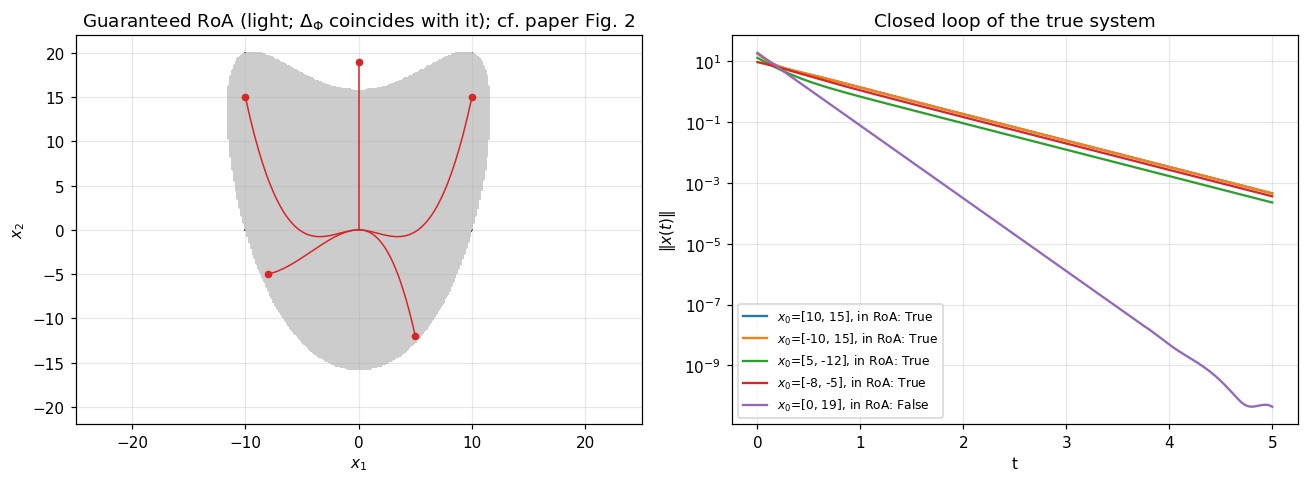

In [3]:
g1, g2 = np.meshgrid(np.linspace(-25, 25, 301), np.linspace(-22, 22, 265))
G = np.vstack([g1.ravel(), g2.ravel()])
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
ax[0].contourf(g1, g2, ctrl_ex.in_delta_set(G).reshape(g1.shape), levels=[0.5, 1.5], colors=["0.35"])
ax[0].contourf(g1, g2, ctrl_ex.in_roa(G).reshape(g1.shape), levels=[0.5, 1.5], colors=["0.8"])
ax[0].set(xlabel="$x_1$", ylabel="$x_2$", title="Guaranteed RoA (light; $\\Delta_\\Phi$ coincides with it); cf. paper Fig. 2")
for x0 in ([10, 15], [-10, 15], [5, -12], [-8, -5], [0, 19]):
    r = ctrl_ex.simulate_closed_loop(ex, x0, (0, 5), t_eval=np.linspace(0, 5, 501))
    ax[0].plot(r.x[0], r.x[1], "C3", lw=1); ax[0].plot(*x0, "C3o", ms=4)
    ax[1].plot(r.t, np.linalg.norm(r.x, axis=0), label=f"$x_0$={x0}, in RoA: {bool(ctrl_ex.in_roa(np.array(x0, float)))}")
ax[1].set(xlabel="t", ylabel="$\\|x(t)\\|$", yscale="log", title="Closed loop of the true system")
ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

Our EDMD reproduces the paper's $A$, $B_0$ and $B_1$. The controller has $L_w \approx 0$, as in the paper; it is exactly 0 with the exact matrices. As the paper notes for this example, the RoA coincides with the set of $x$ for which $\hat\Phi(x) \in \Delta_\Phi$, so the dark $\Delta_\Phi$ region is hidden under the RoA in the plot. The gain and the region of attraction are close to the paper's. The LMIs only define a feasible set, so `objective='logdet'` (the default) picks the solution with the largest RoA volume; a plain feasibility solution can have an arbitrarily small RoA.

---
## Part 2. Bilinear EDMD of the CSTR

### 2.1 System and coordinates

We use the CSTR from `test_dynamics.ipynb`, shifted to its unstable steady state and scaled by nominal values ($z$, $v$).

Strässer's error bound and the uncertainty set $\Delta_\Phi$ use Euclidean norms. In the nominal scaling, though, $z_2$ (temperature) varies about 10 times less than $z_1$ on a meaningful region. We therefore apply one more diagonal scaling, `transform`, so that the sampling box becomes $[-1, 1]^2$: $z = D_L w$ with $D_L = \mathrm{diag}(0.09,\ 0.009)$. In physical units this box is $C_A$ within ±9% and $T$ within ±0.9% (≈ ±3.8 K) of nominal. The inputs keep the nominal scaling.

In [4]:
V, k0, E, Rg = 1.0, 8.46e6, 5.0e4, 8.314
dH, rho, cp  = -1.15e4, 1000.0, 0.231
T0, CA0      = 300.0, 4.0

def f0(x):
    CA, T = x
    r = k0 * np.exp(-E / (Rg * T)) * CA
    return np.array([-r, -dH / (rho * cp) * r])

def f1(x):
    CA, T = x
    return np.array([(CA0 - CA) / V, (T0 - T) / V])

def f2(x):
    return np.array([0.0, 1.0 / (rho * cp * V)])

cstr = InputAffineSystem(f0, [f1, f2], 2, 2, name="CSTR", x_test=[2.0, 400.0])
s = cstr.shift_to_steady_state([5.0, 2.0e4], x_guess=[1.95, 402.0], scaling="nominal", name="CSTR (nominal)")
L_box = np.array([0.09, 0.009])
w = s.transform(np.zeros(2), L_box, np.zeros(2), np.ones(2), name="CSTR (box-normalized)")
print(w)
A_true, B_true = w.linearize()
print("true linearization: A =\n", A_true, "\nB =\n", B_true, "\neig(A) =", np.linalg.eigvals(A_true))

System CSTR (box-normalized): n = 2, m = 2
  x = x_offset + x_scale * z,  x_offset = [  1.87865 422.9245 ],  x_scale = [0.16908 3.80632]
  u = u_offset + u_scale * v,  u_offset = [    5. 20000.],  u_scale = [    5. 20000.]
true linearization: A =
 [[-10.646   -8.0285]
 [ 12.4855  12.7543]] 
B =
 [[  62.7329    0.    ]
 [-161.4742   22.7464]] 
eig(A) = [-5.      7.1083]


### 2.2 Data and EDMD with several dictionaries

- **Data:** 1000 uniform samples in $[-1,1]^2$, with flows of $\tilde f_0$, $\tilde f_1$, $\tilde f_2$ on $[0, 0.01]$ h. We use snapshot pairs with $\Delta t = 10^{-3}$ h.
- **Dictionaries:** monomials of degree 1 (the state only), 2 and 3.
- **Diagnostics:**
  - the error of the state block of $A$ against the true Jacobian, and of $B_0$ against $G(0)$;
  - the empirical constant $c_r$ of the proportional error bound $\|r\| \le c_r(\|\hat\Phi\| + \|u\|)$, computed from the true vector fields on 3000 test points. This is a sampled estimate, not the paper's probabilistic bound.

In [5]:
data = w.collect_data(1000, 1.0, tau=0.01, n_time=11, rng=0, solver="RK45", rtol=1e-10, atol=1e-12)
X_test = w.sample_hypercube(3000, 1.0, rng=5)
rng = np.random.default_rng(0)
dictionaries = {
    "monomials, deg 1": MonomialDictionary(2, 1),
    "monomials, deg 2": MonomialDictionary(2, 2),
    "monomials, deg 3": MonomialDictionary(2, 3),
}
models = {}
for name, d in dictionaries.items():
    mdl = bilinear_edmd(data, d, dt_index=1, report=False)
    models[name] = mdl
    eb = mdl.empirical_error_bound(w, X_test)
    print(f"{name:17s} N = {d.N:2d} | |A_xx - A_true| = {np.max(np.abs(mdl.A[:2, :2] - A_true)):.2e} | "
          f"|B0_x - B_true| = {np.max(np.abs(mdl.B0[:2] - B_true)):.1e} | c_r (drift) = {eb['rho_drift']:.3g}, "
          f"(inputs) = {eb['rho_inputs']:.1e} | eig(A) = {np.round(np.sort(np.linalg.eigvals(mdl.A).real), 2)}")

[CSTR (box-normalized)] data collection: 1000 samples x 3 vector fields: total computational time = 7.4823 s


monomials, deg 1  N =  2 | |A_xx - A_true| = 9.48e-03 | |B0_x - B_true| = 4.2e-10 | c_r (drift) = 2.04, (inputs) = 5.1e-10 | eig(A) = [-5.   7.1]


monomials, deg 2  N =  5 | |A_xx - A_true| = 3.09e-02 | |B0_x - B_true| = 8.6e-10 | c_r (drift) = 1.74, (inputs) = 9.9e-10 | eig(A) = [-10.    -5.     1.96   7.16  14.34]


monomials, deg 3  N =  9 | |A_xx - A_true| = 2.93e-05 | |B0_x - B_true| = 8.6e-10 | c_r (drift) = 1.19, (inputs) = 1.3e-09 | eig(A) = [-15.   -10.    -5.    -3.47   2.23   7.11   9.58  14.31  21.34]


The input fields $\tilde f_1$ and $\tilde f_2$ are affine in the state, so every monomial dictionary represents them exactly: their residual is about zero. All the error is in the drift, and it decreases with the polynomial degree.

The eigenvalues show the structure of a lifting of a polynomial dictionary at an equilibrium. The degree-$k$ monomials add eigenvalues that are sums of $k$ eigenvalues of the true linearization, such as $2\times 7.1$. This matters for control in Part 3.

### 2.3 Prediction accuracy

We compare the lifted models with the true system under a constant input, from a few initial conditions. The origin is unstable, so all trajectories leave the box; we use a short horizon of 0.15 h.

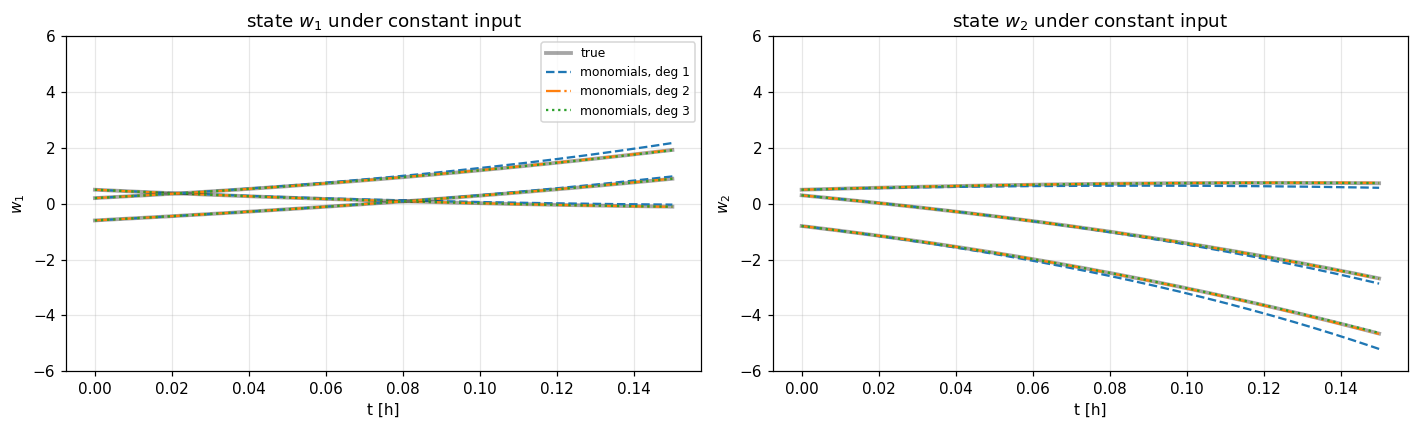

median max-error over [0, 0.05] h from 50 initial states in [-0.5, 0.5]^2:
   monomials, deg 1 : 5.031e-03
   monomials, deg 2 : 8.232e-04
   monomials, deg 3 : 2.633e-05


In [6]:
t_eval = np.linspace(0, 0.15, 151)
v_const = np.array([0.05, -0.05])
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for k, x0 in enumerate(([0.5, 0.5], [-0.6, 0.3], [0.2, -0.8])):
    r = w.simulate(x0, (0, 0.15), u=v_const, t_eval=t_eval)
    for i in range(2):
        ax[i].plot(r.t, r.x[i], "k", lw=2.5, alpha=0.35, label="true" if k == 0 else None)
    for (name, mdl), ls in zip(models.items(), ["--", "-.", ":"]):
        rl = mdl.simulate(x0, (0, 0.15), u=v_const, t_eval=t_eval)
        for i in range(2):
            ax[i].plot(rl.t, rl.x[i], ls=ls, color=f"C{list(models).index(name)}",
                       label=name if k == 0 else None)
for i in range(2):
    ax[i].set(xlabel="t [h]", ylabel=f"$w_{i+1}$", ylim=(-6, 6), title=f"state $w_{i+1}$ under constant input")
ax[0].legend(fontsize=8)
plt.tight_layout(); plt.show()

errs = {}
for name, mdl in models.items():
    e = []
    for x0 in w.sample_hypercube(50, 0.5, rng=11).T:
        r = w.simulate(x0, (0, 0.05), u=v_const, t_eval=np.linspace(0, 0.05, 11))
        rl = mdl.simulate(x0, (0, 0.05), u=v_const, t_eval=r.t)
        e.append(np.max(np.abs(r.x - rl.x)))
    errs[name] = np.median(e)
print("median max-error over [0, 0.05] h from 50 initial states in [-0.5, 0.5]^2:")
for name, e in errs.items():
    print(f"   {name:17s}: {e:.3e}")

---
## Part 3. Controller synthesis on the CSTR surrogate

### 3.1 Strässer et al., Theorem 7, with the state-only dictionary

- **Setting:** $\hat\Phi(x) = x$, $c_r$ equal to its empirical value, $Q_z = -I$, $S_z = 0$, and $R_z = \max\|\hat\Phi\|^2$ over the box, so that $\Delta_\Phi$ covers the box.
- **Model:** the surrogate is still bilinear, since the flow-rate input gives $B_1 = -5I \neq 0$, and it is exact in the input fields.
- **Comparison:** the resulting rational feedback $\mu(x)$ against the LQR of the true linearization.

In [7]:
mdl1 = models["monomials, deg 1"]
cr1 = mdl1.empirical_error_bound(w, X_test)["c_r"]
Rz1 = float(np.max(np.sum(mdl1.lift(X_test) ** 2, axis=0)))
ctrl = EdmdRobustController(mdl1, c_r=cr1, R_z=Rz1, flexible=True)
print(ctrl)
print("K =\n", ctrl.K, "\nK_w =\n", ctrl.K_w)
print(f"fraction of the sampling box inside the guaranteed RoA: {ctrl.in_roa(X_test).mean():.3f}")

K_lqr = w.design_lqr(np.eye(2), np.eye(2))
print("true-linearization LQR gain:\n", K_lqr)

[EDMD robust (Strasser et al.)] LMI synthesis: status = optimal, N = 2, m = 2, c_r = 2.04: computational time = 0.038 s
EdmdRobustController(N=2, c_r=2.04, status='optimal')
K =
 [[0.0927 0.1129]
 [0.146  0.0317]] 
K_w =
 [[ 0.0762 -0.0013  0.      0.    ]
 [ 0.5372  0.2096  0.      0.    ]]
fraction of the sampling box inside the guaranteed RoA: 1.000
true-linearization LQR gain:
 [[ 0.3673 -0.9731]
 [ 0.4261  0.3026]]


[CSTR (box-normalized)] closed loop (EDMD robust (Strasser et al.)) simulation on t = [0, 1]: total computational time = 0.1507 s


[CSTR (box-normalized)] closed loop (v = -K z) simulation on t = [0, 1]: total computational time = 0.2439 s
[CSTR (box-normalized)] closed loop (EDMD robust (Strasser et al.)) simulation on t = [0, 1]: total computational time = 0.1607 s


[CSTR (box-normalized)] closed loop (v = -K z) simulation on t = [0, 1]: total computational time = 0.3088 s
[CSTR (box-normalized)] closed loop (EDMD robust (Strasser et al.)) simulation on t = [0, 1]: total computational time = 0.1042 s


[CSTR (box-normalized)] closed loop (v = -K z) simulation on t = [0, 1]: total computational time = 0.1222 s
[CSTR (box-normalized)] closed loop (EDMD robust (Strasser et al.)) simulation on t = [0, 1]: total computational time = 0.1199 s


[CSTR (box-normalized)] closed loop (v = -K z) simulation on t = [0, 1]: total computational time = 0.2038 s
[CSTR (box-normalized)] closed loop (EDMD robust (Strasser et al.)) simulation on t = [0, 1]: total computational time = 0.1490 s


[CSTR (box-normalized)] closed loop (v = -K z) simulation on t = [0, 1]: total computational time = 0.1357 s


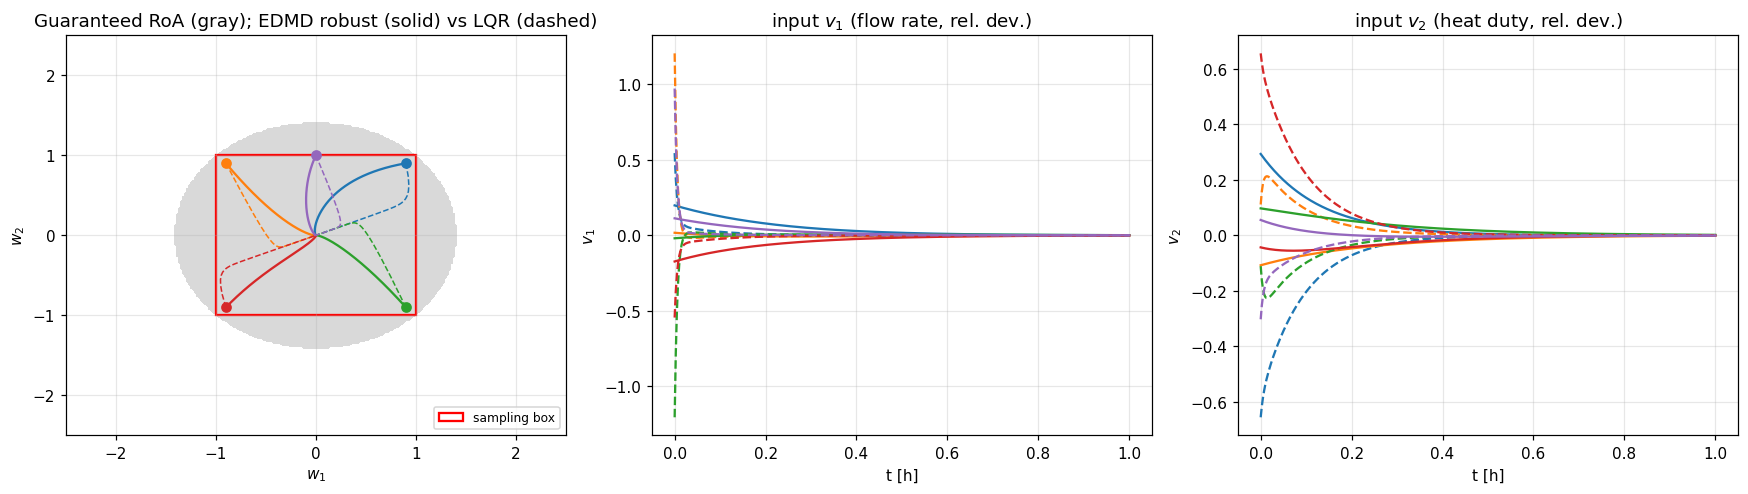

x0 = [0.9, 0.9]: cost EDMD robust = 0.2042,  cost LQR (true linearization) = 0.0810
x0 = [-0.9, 0.9]: cost EDMD robust = 0.1612,  cost LQR (true linearization) = 0.0237
x0 = [0.9, -0.9]: cost EDMD robust = 0.1830,  cost LQR (true linearization) = 0.0258
x0 = [-0.9, -0.9]: cost EDMD robust = 0.1594,  cost LQR (true linearization) = 0.0891
x0 = [0.0, 1.0]: cost EDMD robust = 0.1215,  cost LQR (true linearization) = 0.0131


In [8]:
g1, g2 = np.meshgrid(np.linspace(-2.5, 2.5, 251), np.linspace(-2.5, 2.5, 251))
G = np.vstack([g1.ravel(), g2.ravel()])
x0_list = [[0.9, 0.9], [-0.9, 0.9], [0.9, -0.9], [-0.9, -0.9], [0.0, 1.0]]
t_eval = np.linspace(0, 1.0, 401)

fig, ax = plt.subplots(1, 3, figsize=(16, 4.6))
ax[0].contourf(g1, g2, ctrl.in_roa(G).reshape(g1.shape), levels=[0.5, 1.5], colors=["0.85"])
ax[0].add_patch(plt.Rectangle((-1, -1), 2, 2, fill=False, ec="r", lw=1.5, label="sampling box"))
cl_rob, cl_lqr = [], []
for k, x0 in enumerate(x0_list):
    r = ctrl.simulate_closed_loop(w, x0, (0, 1.0), t_eval=t_eval)
    rl = w.simulate_closed_loop(x0, (0, 1.0), t_eval=t_eval)
    cl_rob.append(r); cl_lqr.append(rl)
    ax[0].plot(r.x[0], r.x[1], color=f"C{k}", lw=1.5); ax[0].plot(rl.x[0], rl.x[1], "--", color=f"C{k}", lw=1)
    ax[0].plot(*x0, "o", color=f"C{k}")
    ax[1].plot(r.t, r.u[0], color=f"C{k}"); ax[1].plot(rl.t, rl.u[0], "--", color=f"C{k}")
    ax[2].plot(r.t, r.u[1], color=f"C{k}"); ax[2].plot(rl.t, rl.u[1], "--", color=f"C{k}")
ax[0].set(xlabel="$w_1$", ylabel="$w_2$", title="Guaranteed RoA (gray); EDMD robust (solid) vs LQR (dashed)")
ax[0].legend(loc="lower right", fontsize=8)
ax[1].set(xlabel="t [h]", ylabel="$v_1$", title="input $v_1$ (flow rate, rel. dev.)")
ax[2].set(xlabel="t [h]", ylabel="$v_2$", title="input $v_2$ (heat duty, rel. dev.)")
plt.tight_layout(); plt.show()

# Cost comparison with the quadratic cost of the paper's comparison controllers (Q = R = I in w, v)
from scipy.integrate import trapezoid
def cost(r): return trapezoid(np.sum(r.x ** 2, 0) + np.sum(r.u ** 2, 0), r.t)
for x0, r, rl in zip(x0_list, cl_rob, cl_lqr):
    print(f"x0 = {x0}: cost EDMD robust = {cost(r):.4f},  cost LQR (true linearization) = {cost(rl):.4f}")

The certified design stabilizes the CSTR from the corners of the box. However, it is designed for stability, not performance: its cost is not optimized, and the comparison above shows the price.

### 3.2 Richer dictionaries: infeasibility of the robust design

With degree-2 and degree-3 monomials, the surrogate is more accurate (Part 2), but the LMIs of Theorem 7 become infeasible, even when $c_r$ is far below its empirical value. The reason is structural.

- **Why the extra modes are a problem:**
  - The extra observables, such as $x_1^2$ and $x_1x_2$, have zero gradient at the origin, so their rows of $B_0$ vanish.
  - Their lifted eigenvalues are sums of the true ones, e.g. $\lambda_1+\lambda_2 \approx 2.1$, $2\lambda_2 \approx 14.2$ and $3\lambda_2 \approx 21.3$, so several are **unstable**.
  - These modes are reached only through weak couplings in $A$: the PBH test $\sigma_{\min}[A - \lambda I,\ B_0]$ is small. LQR on $(A, B_0)$ therefore needs huge gains, and the robust LMIs cannot tolerate both these modes and the bilinear uncertainty $\Delta_\Phi$.
- **Why the uncertainty set is conservative:** $\Delta_\Phi$ treats $\hat\Phi(x)$ as an arbitrary vector in a ball and forgets that, for example, $x_1^2$ is determined by $x_1$.

In [9]:
print(f"{'dictionary':17s} {'N':>3s} {'c_r(emp)':>9s}  {'LMI status at c_r(emp)':28s} {'LMI status at c_r=1e-3':28s} "
      f"{'min PBH sigma':>14s} {'|K_LQR(A,B0)|':>14s}")
for name, mdl in models.items():
    cr = mdl.empirical_error_bound(w, X_test)["c_r"]
    Rz = float(np.max(np.sum(mdl.lift(X_test) ** 2, axis=0)))
    st1 = EdmdRobustController(mdl, c_r=cr, R_z=Rz, report=False).status.split(' ')[0]
    st2 = EdmdRobustController(mdl, c_r=1e-3, R_z=Rz, report=False).status.split(' ')[0]
    ev = np.linalg.eigvals(mdl.A)
    pbh = min(np.linalg.svd(np.hstack([mdl.A - l * np.eye(mdl.N), mdl.B0]), compute_uv=False)[-1]
              for l in ev if l.real > 0)
    try:
        kn = np.linalg.norm(EdmdLQR(mdl, np.eye(2), np.eye(2)).K)
    except Exception:
        kn = np.inf
    print(f"{name:17s} {mdl.N:3d} {cr:9.3g}  {st1[:28]:28s} {st2[:28]:28s} {pbh:14.2e} {kn:14.3g}")

dictionary          N  c_r(emp)  LMI status at c_r(emp)       LMI status at c_r=1e-3        min PBH sigma  |K_LQR(A,B0)|


monomials, deg 1    2      2.04  optimal                      optimal                            1.55e+01           1.16


monomials, deg 2    5      1.74  solver_error                 solver_error                       3.33e-01           59.8


monomials, deg 3    9      1.19  solver_error                 solver_error                       2.78e-03       8.17e+04


### 3.3 LQR on the linear part of the surrogate

A common baseline that comes without guarantees is $u = -K\hat\Phi(x)$, where $K$ is the LQR gain of $(A, B_0)$ with $Q_{lift} = C^\top Q C$ acting on the state part. For the state-only dictionary this is essentially the LQR of the true linearization. For richer dictionaries the gain becomes large, for the reason explained in 3.2. Here, with degree 2, the closed loop of the true CSTR even **diverges**: the feedback acts on lifted modes that the true system does not have.

[CSTR (box-normalized)] closed loop (v = -K z) simulation on t = [0, 1]: total computational time = 0.1360 s
[CSTR (box-normalized)] closed loop (EDMD LQR (linear part)) simulation on t = [0, 1]: total computational time = 0.1636 s
monomials, deg 1: |K| = 1.16, final |w| = 3.61e-05, cost = 0.0810  (true LQR cost 0.0810)


[CSTR (box-normalized)] closed loop (EDMD LQR (linear part)) simulation on t = [0, 1]: total computational time = 0.4232 s
monomials, deg 2: |K| = 59.8, final |w| = 3.79e+01, cost = 789612719.3605  (true LQR cost 0.0810)


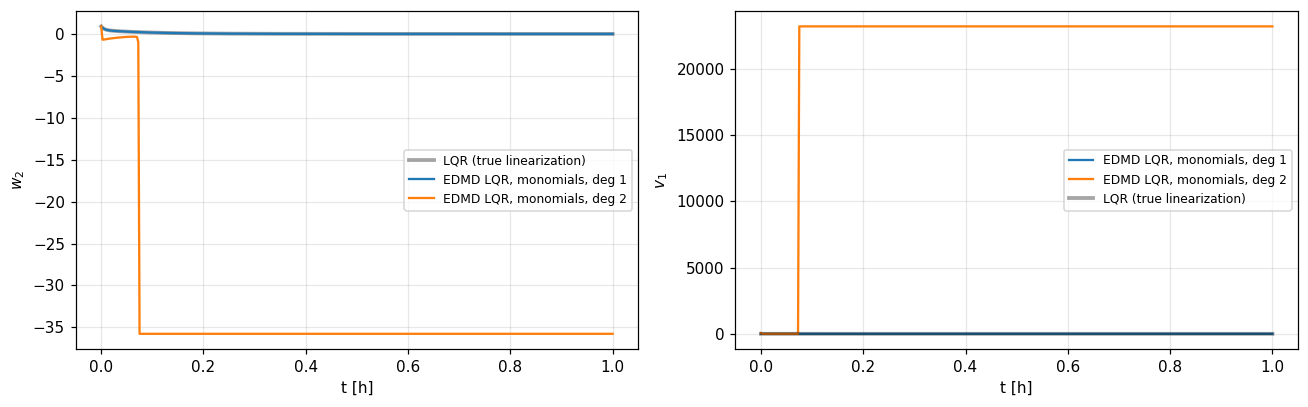

In [10]:
x0 = np.array([0.9, 0.9])
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
r_true = w.simulate_closed_loop(x0, (0, 1.0), t_eval=t_eval)
ax[0].plot(r_true.t, r_true.x[1], "k", lw=2.5, alpha=0.35, label="LQR (true linearization)")
for name in ("monomials, deg 1", "monomials, deg 2"):
    klqr = EdmdLQR(models[name], np.eye(2), np.eye(2))
    r = klqr.simulate_closed_loop(w, x0, (0, 1.0), t_eval=t_eval)
    print(f"{name}: |K| = {np.linalg.norm(klqr.K):.3g}, final |w| = {np.linalg.norm(r.x[:, -1]):.2e}, "
          f"cost = {cost(r):.4f}  (true LQR cost {cost(r_true):.4f})")
    ax[0].plot(r.t, r.x[1], label=f"EDMD LQR, {name}")
    ax[1].plot(r.t, r.u[0], label=f"EDMD LQR, {name}")
ax[1].plot(r_true.t, r_true.u[0], "k", lw=2.5, alpha=0.35, label="LQR (true linearization)")
ax[0].set(xlabel="t [h]", ylabel="$w_2$"); ax[1].set(xlabel="t [h]", ylabel="$v_1$")
ax[0].legend(fontsize=8); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

---
## Part 4. EDMD MPC (bilinear surrogate) on an example with an exact bilinear lifting

### 4.1 The example and its exact bilinear EDMD model

$$
\dot x_1 = \rho x_1 + u, \qquad \dot x_2 = \lambda (x_2 - x_1^2) + (1 + x_1)\,u, \qquad \rho = -1,\ \lambda = 1 .
$$

The origin is open-loop unstable, the input field depends on the state, and the linearization is controllable.

With $\hat\Phi(x) = [x_1,\ x_2,\ x_1^2]$, both vector fields map the observables into $\mathrm{span}\{1, \hat\Phi\}$, since $\nabla(x_1^2)\cdot f_0 = 2\rho x_1^2$ and $\nabla(x_1^2)\cdot f_1 = 2x_1$. The lifted model is therefore exactly bilinear:

$$
A = \begin{bmatrix}\rho&0&0\\0&\lambda&-\lambda\\0&0&2\rho\end{bmatrix},\quad
B_0 = \begin{bmatrix}1\\1\\0\end{bmatrix},\quad
B_1 = \begin{bmatrix}0&0&0\\1&0&0\\2&0&0\end{bmatrix}.
$$

In [11]:
from mpc import ModelPredictiveControl
from edmd import EdmdMPC
from scipy.integrate import trapezoid

rho_b, lam_b = -1.0, 1.0
bil = InputAffineSystem(lambda x: np.array([rho_b * x[0], lam_b * (x[1] - x[0] ** 2)]),
                        [lambda x: np.array([1.0, 1.0 + x[0]])], 2, 1, name="exact-bilinear example")
dict_b = CustomDictionary(2, [lambda x: x[0] ** 2], names=["x1^2"])
data_b = bil.collect_data(2000, 2.0, tau=0.01, n_time=11, rng=0, solver="RK45", rtol=1e-11, atol=1e-13)
model_b = bilinear_edmd(data_b, dict_b, dt_index=1)
A_ex = np.array([[rho_b, 0, 0], [0, lam_b, -lam_b], [0, 0, 2 * rho_b]])
B0_ex = np.array([[1.0], [1.0], [0.0]])
B1_ex = np.array([[0, 0, 0], [1.0, 0, 0], [2.0, 0, 0]])
print("A =\n", model_b.A, "\nB0 =", model_b.B0.ravel(), "\nB1 =\n", model_b.B[0])
print(f"errors vs exact: A {np.max(np.abs(model_b.A - A_ex)):.1e}, B0 {np.max(np.abs(model_b.B0 - B0_ex)):.1e}, "
      f"B1 {np.max(np.abs(model_b.B[0] - B1_ex)):.1e}")
print("empirical c_r on [-2, 2]^2:", model_b.empirical_error_bound(bil, bil.sample_hypercube(2000, 2.0, rng=3)))

[exact-bilinear example] data collection: 2000 samples x 2 vector fields: total computational time = 1.4205 s
[bilinear EDMD] N = 3, dt = 0.001: total computational time = 0.0111 s
A =
 [[-1.  0. -0.]
 [ 0.  1. -1.]
 [-0. -0. -2.]] 
B0 = [1. 1. 0.] 
B1 =
 [[0. 0. 0.]
 [1. 0. 0.]
 [2. 0. 0.]]
errors vs exact: A 5.5e-13, B0 4.7e-13, B1 1.5e-12
empirical c_r on [-2, 2]^2: {'c_r': np.float64(5.348562256628603e-10), 'rho_drift': np.float64(2.445044165422724e-10), 'rho_inputs': np.float64(5.348562256628603e-10)}


### 4.2 EDMD MPC vs nonlinear MPC on the true model

`EdmdMPC(model, horizon, dt, Q, R, P, ...)` lifts the measured state, $z = \hat\Phi(x)$, predicts with the bilinear model, and weights only the state part $x = Cz$ in the stage cost. We use $N = 20$, $\Delta t = 0.1$ and $Q = I$, $R = 1$.

- **Same terminal cost:** we take $P_{lift} = C^\top P_x C$, where $P_x$ is the LQR Riccati solution of the true linearization, i.e. the default of `mpc.py`. Because the lifting is exact, the EDMD MPC must then reproduce the nonlinear MPC. Small differences can remain only because RK4 is applied in different coordinates.
- **Default terminal cost:** `P='lqr'`, the Riccati solution of the lifted linear part $(A, B_0)$ with $Q_{lift} = C^\top Q C$. This is a different, but also valid, terminal cost.

EdmdMPC(N_obs=3, horizon=20, dt=0.1) 
P_lift (lifted LQR) =
 [[ 0.5    -0.5     0.1667]
 [-0.5     3.2321 -0.988 ]
 [ 0.1667 -0.988   0.3253]]

OCP at x0 = [ 1.5 -1.5]: max |u_EdmdMPC - u_NMPC| = 8.4e-08, costs 9.588791 vs 9.588791;  lifted-LQR terminal: cost 9.840195
max |predicted x (lifted) - predicted x (NMPC)| = 5.3e-08,  predicted z3 - x1^2 = 4.2e-08


[MPC: exact-bilinear example] closed loop, 60 steps: total computational time = 0.4975 s (OCP solves 0.2199 s, mean 0.0037 s, max 0.0163 s per step)


[EDMD MPC (bilinear surrogate): exact-bilinear example] closed loop, 60 steps: total computational time = 0.3545 s (OCP solves 0.2086 s, mean 0.0035 s per step)


[EDMD MPC (bilinear surrogate): exact-bilinear example] closed loop, 60 steps: total computational time = 0.3840 s (OCP solves 0.2178 s, mean 0.0036 s per step)
closed loop: max |x_EdmdMPC - x_NMPC| at samples = 3.1e-08


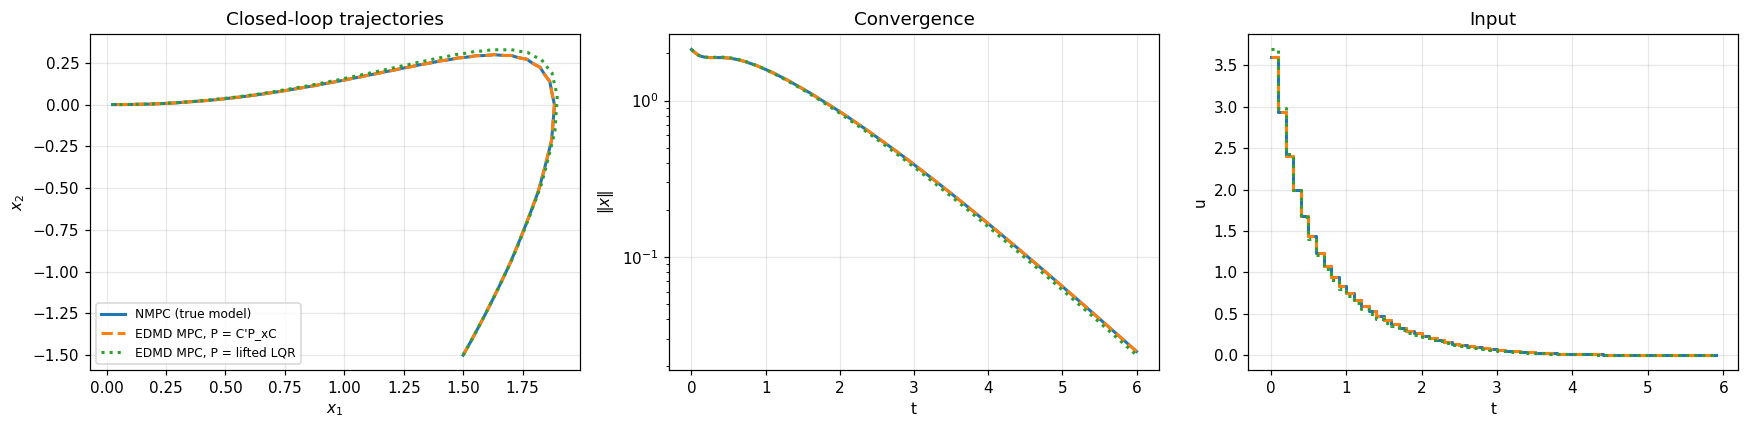

In [12]:
_ = bil.design_lqr(np.eye(2), np.eye(1))
Px = bil.P
Cmat = np.hstack([np.eye(2), np.zeros((2, 1))])
dt_b, N_b = 0.1, 20
nmpc = ModelPredictiveControl(bil, N_b, dt_b, P=Px)                     # true model
bmpc = EdmdMPC(model_b, N_b, dt_b, P=Cmat.T @ Px @ Cmat)            # same terminal cost
bmpc_lqr = EdmdMPC(model_b, N_b, dt_b)                              # P = lifted LQR
print(bmpc, "\nP_lift (lifted LQR) =\n", bmpc_lqr.P)

x0_b = np.array([1.5, -1.5])
s_n, s_b, s_l = nmpc.solve(x0_b), bmpc.solve(x0_b), bmpc_lqr.solve(x0_b)
print(f"\nOCP at x0 = {x0_b}: max |u_EdmdMPC - u_NMPC| = {np.max(np.abs(s_b.u - s_n.u)):.1e}, "
      f"costs {s_b.cost:.6f} vs {s_n.cost:.6f};  lifted-LQR terminal: cost {s_l.cost:.6f}")
print(f"max |predicted x (lifted) - predicted x (NMPC)| = {np.max(np.abs(s_b.x[:2] - s_n.x)):.1e},  "
      f"predicted z3 - x1^2 = {np.max(np.abs(s_b.x[2] - s_b.x[0] ** 2)):.1e}")

r_n = nmpc.simulate_closed_loop(x0_b, 60, n_fine=20)
r_b = bmpc.simulate_closed_loop(bil, x0_b, 60, n_fine=20)
r_l = bmpc_lqr.simulate_closed_loop(bil, x0_b, 60, n_fine=20)
print(f"closed loop: max |x_EdmdMPC - x_NMPC| at samples = {np.max(np.abs(r_b.x_samples - r_n.x_samples)):.1e}")

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
for r, lab, st in ((r_n, "NMPC (true model)", "-"), (r_b, "EDMD MPC, P = C'P_xC", "--"),
                   (r_l, "EDMD MPC, P = lifted LQR", ":")):
    ax[0].plot(r.x[0], r.x[1], st, lw=2, label=lab)
    ax[1].plot(r.t, np.linalg.norm(r.x, axis=0), st, lw=2, label=lab)
    ax[2].step(r.t_samples[:-1], r.u_samples[0], st, where="post", lw=2, label=lab)
ax[0].set(xlabel="$x_1$", ylabel="$x_2$", title="Closed-loop trajectories"); ax[0].legend(fontsize=8)
ax[1].set(xlabel="t", ylabel="$\\|x\\|$", yscale="log", title="Convergence"); ax[2].set(xlabel="t", ylabel="u", title="Input")
plt.tight_layout(); plt.show()

The two MPCs with the same terminal cost coincide, up to RK4 differences between the coordinates.

With the lifted-LQR terminal cost the closed loop also converges, but $x_1$ decays more slowly at the end. That terminal weight contains cross terms such as $x_1\cdot x_1^2$ through $z_3 = x_1^2$, which change the trade-off near the origin.

### 4.3 Constraints, and a comparison with the other EDMD-based controllers

The input gain $1 + x_1$ of the second state vanishes at $x_1 = -1$, so the system loses control authority there. Starting from $x_0 = (-1, 1)$, we impose input bounds $|u| \le 1.5$ and the state constraint $x_2 \le 1.05$, and compare:

- EDMD MPC with the constraints,
- `EdmdLQR` with its input clipped to the bounds,
- `EdmdRobustController` (Strässer et al.) with $c_r = 0.01$ (the model is exact, so $c_r$ only needs to cover small numerical errors) and $R_z = 2$,
- LQR on the true linearization, without bounds.


[EDMD robust (Strasser et al.)] LMI synthesis: status = optimal, N = 3, m = 1, c_r = 0.01: computational time = 0.039 s
EDMD LQR gain: [[ 0.      2.7321 -0.8214]]   (true LQR gain on x: [[0.     2.7321]] )
robust gain K: [[-0.0896 -3.2968  1.5685]]  K_w: [[-0.3536 -0.      0.    ]]


[EDMD MPC (bilinear surrogate): exact-bilinear example] closed loop, 60 steps: total computational time = 0.3587 s (OCP solves 0.2381 s, mean 0.0040 s per step)
[exact-bilinear example] feedback / time-varying input simulation on t = [0, 6]: total computational time = 0.0475 s
[exact-bilinear example] closed loop (EDMD robust (Strasser et al.)) simulation on t = [0, 6]: total computational time = 0.1080 s


[exact-bilinear example] closed loop (v = -K z) simulation on t = [0, 2.245]: total computational time = 0.2900 s

controller                            cost   max x2  max |u|    |x(T)|
EDMD MPC (constrained)              6.4771        1    1.500   2.4e-02
EDMD LQR, clipped input             6.4805        1    1.500   2.2e-02
EDMD robust (Strasser et al.)       6.3713        1    2.535   5.8e-02
LQR (true linearization)         68162499.5166 5.62e+04 153505.707   5.6e+04


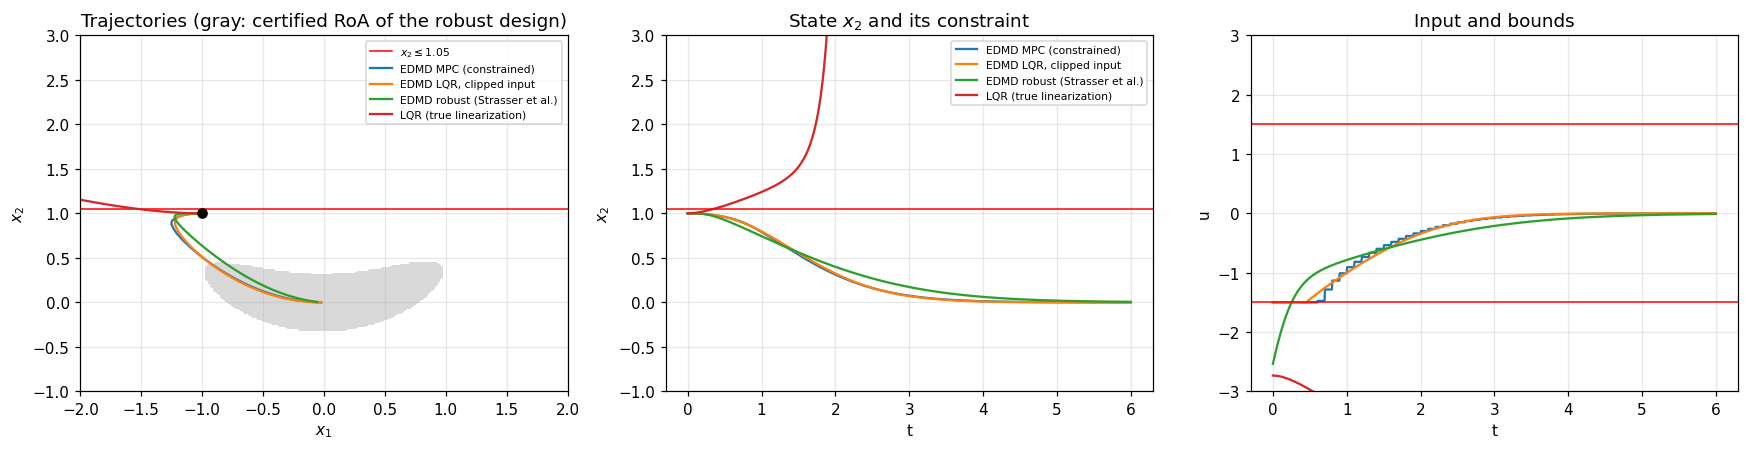

In [13]:
u_b, x2_max = 1.5, 1.05
bmpc_c = EdmdMPC(model_b, N_b, dt_b, P=Cmat.T @ Px @ Cmat, u_min=-u_b, u_max=u_b, x_max=[np.inf, x2_max])
edmd_lqr = EdmdLQR(model_b, np.eye(2), np.eye(1))
rob = EdmdRobustController(model_b, c_r=0.01, R_z=2.0)
print("EDMD LQR gain:", edmd_lqr.K, "  (true LQR gain on x:", bil.K, ")")
print("robust gain K:", rob.K, " K_w:", rob.K_w)

x0_c = np.array([-1.0, 1.0])
T_end = 6.0
t_ev = np.linspace(0, T_end, 1201)
res = {
    "EDMD MPC (constrained)": bmpc_c.simulate_closed_loop(bil, x0_c, int(T_end / dt_b), n_fine=20),
    "EDMD LQR, clipped input": bil.simulate(x0_c, (0, T_end), u=lambda t, x: np.clip(edmd_lqr(x), -u_b, u_b), t_eval=t_ev),
    "EDMD robust (Strasser et al.)": rob.simulate_closed_loop(bil, x0_c, (0, T_end), t_eval=t_ev),
    "LQR (true linearization)": bil.simulate_closed_loop(x0_c, (0, T_end), t_eval=t_ev),
}

def cl_cost(r):
    return trapezoid(np.sum(r.x ** 2, 0) + np.sum(r.u ** 2, 0), r.t)

print(f"\n{'controller':32s} {'cost':>9s} {'max x2':>8s} {'max |u|':>8s} {'|x(T)|':>9s}")
for name, r in res.items():
    print(f"{name:32s} {cl_cost(r):9.4f} {r.x[1].max():8.3g} {np.max(np.abs(r.u)):8.3f} {np.linalg.norm(r.x[:, -1]):9.1e}")

g1, g2 = np.meshgrid(np.linspace(-2, 2, 201), np.linspace(-1, 3, 201))
roa = rob.in_roa(np.vstack([g1.ravel(), g2.ravel()])).reshape(g1.shape)
fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))
ax[0].contourf(g1, g2, roa, levels=[0.5, 1.5], colors=["0.85"])
ax[0].axhline(x2_max, color="r", lw=1, label="$x_2 \\leq 1.05$")
for k, (name, r) in enumerate(res.items()):
    ax[0].plot(r.x[0], r.x[1], color=f"C{k}", label=name)
    ax[1].plot(r.t, r.x[1], color=f"C{k}", label=name)
    ax[2].plot(r.t, r.u[0], color=f"C{k}", label=name)
ax[0].plot(*x0_c, "ko")
ax[0].set(xlabel="$x_1$", ylabel="$x_2$", xlim=(-2, 2), ylim=(-1, 3), title="Trajectories (gray: certified RoA of the robust design)")
ax[1].axhline(x2_max, color="r", lw=1); ax[1].set(xlabel="t", ylabel="$x_2$", ylim=(-1, 3), title="State $x_2$ and its constraint")
ax[2].axhline(u_b, color="r", lw=1); ax[2].axhline(-u_b, color="r", lw=1)
ax[2].set(xlabel="t", ylabel="u", title="Input and bounds", ylim=(-3, 3))
ax[0].legend(fontsize=7, loc="upper right"); ax[1].legend(fontsize=7)
plt.tight_layout(); plt.show()

**Observations.**

- **LQR on the true linearization diverges** from $x_0 = (-1, 1)$, and the ODE solver stops near $t \approx 2.2$ at a finite escape time. It is designed for the input gain at the origin, $1 + x_1 = 1$, but the actual gain near $x_1 = -1$ is close to zero.
- **The EDMD MPC** stabilizes the system and respects $|u| \le 1.5$. The bound $x_2 \le 1.05$ is respected but not active here, since $x_2$ decreases from its initial value.
- **The clipped EDMD LQR performs almost like the MPC.** Its gain contains a term in $z_3 = x_1^2$, $u = -2.73x_2 + 0.82x_1^2$, a nonlinear feedback that the true-linearization LQR lacks.
- **The robust design** (Strässer et al.) also stabilizes from $x_0$, which lies outside its certified RoA, but it does not handle input bounds and uses $|u|$ up to about 2.5.